# CS 370 A3 Q5 — MassSpring (completed)
Filled in dynamics, initial conditions, and ground event.

In [2]:
# Import libraries
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

## Parameters

In [4]:
g = -9.81
m1 = 1.0
m2 = 5.0
l0 = 4.0
k = 3.0
t0 = 0.0
tfinal = 30.0

## Dynamics function

In [5]:
def dynamics_function(t, z):
    # z = [x1, y1, x2, y2, u1, v1, u2, v2]
    x1, y1, x2, y2, u1, v1, u2, v2 = z

    Delta = np.array([x1 - x2, y1 - y2], dtype=float)
    lcur = np.linalg.norm(Delta)

    # Avoid division-by-zero if the projectiles ever coincide exactly.
    if lcur == 0.0:
        d = np.array([0.0, 0.0], dtype=float)
    else:
        d = Delta / lcur

    F12 = -k * (lcur - l0) * d
    F21 = -F12

    dzdt = np.array([
        u1,                       # x1'
        v1,                       # y1'
        u2,                       # x2'
        v2,                       # y2'
        F12[0] / m1,              # u1'
        g + F12[1] / m1,          # v1'
        F21[0] / m2,              # u2'
        g + F21[1] / m2           # v2'
    ], dtype=float)

    return dzdt

## Event function (stop when either projectile hits the ground)

In [6]:
def ground_event(t, z):
    y1 = z[1]
    y2 = z[3]
    miny = min(y1, y2)
    return miny

ground_event.terminal = True
ground_event.direction = -1

## Initial conditions and solve

In [7]:
# Initial conditions from the assignment statement
z0 = np.array([
    0.0,   25.0,   # x1(0), y1(0)
    5.0,   25.0,   # x2(0), y2(0)
    2.0,   20.0,   # u1(0), v1(0)
   -0.5,   30.0    # u2(0), v2(0)
], dtype=float)

tspan = (t0, tfinal)

sol = solve_ivp(
    dynamics_function,
    tspan,
    z0,
    max_step=0.05,
    events=ground_event
)

print("Solver status:", sol.status)
print("Final time:", sol.t[-1])
if len(sol.t_events[0]) > 0:
    print("Ground impact event time:", sol.t_events[0][0])

Solver status: 1
Final time: 6.4140529853583645
Ground impact event time: 6.4140529853583645


## Static trajectory plot

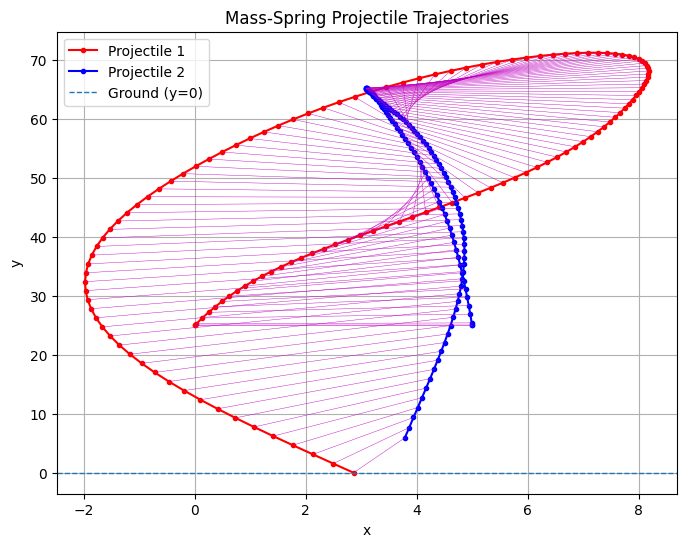

In [8]:
plt.figure(figsize=(8,6))

# Projectile trajectories
plt.plot(sol.y[0], sol.y[1], 'r-o', markersize=3, label='Projectile 1')
plt.plot(sol.y[2], sol.y[3], 'b-o', markersize=3, label='Projectile 2')

# Spring segments over time
for i in range(len(sol.t)):
    plt.plot([sol.y[0][i], sol.y[2][i]], [sol.y[1][i], sol.y[3][i]], 'm-', linewidth=0.3)

plt.axhline(0.0, linestyle='--', linewidth=1, label='Ground (y=0)')
plt.xlabel("x")
plt.ylabel("y")
plt.title("Mass-Spring Projectile Trajectories")
plt.legend()
plt.grid(True)
plt.show()